In [82]:
import os
import operator
from typing import Annotated, Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

from langchain_ollama import OllamaEmbeddings
from langchain_ollama import ChatOllama
embeddings = OllamaEmbeddings(
    model="nomic-embed-text"
)

agent_llm = ChatOllama(
    model="qwen3:0.6b",
    temperature=0
)
llm = ChatOllama(
    model="qwen3:0.6b",
    temperature=0
)



In [63]:
# load the PDF document
loader = PyPDFLoader("./evs_oil_price_shock.pdf")
raw_docs = loader.load()
print(f"Loaded {len(raw_docs)} pages")

incorrect startxref pointer(1)
parsing for Object Streams


Loaded 15 pages


In [64]:
# Section 3 — Text Chunking
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)

print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [65]:
# in-memory only; re-running this cell re-embeds from scratch
vectorstore = Chroma(
    collection_name="rag_conditional",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print("Vector store ready")

Vector store ready


In [66]:
class AgenticRAGState(MessagesState):

    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool

In [67]:
from pydantic import BaseModel, Field

class RouteDecision(BaseModel):
    needs_retrieval: bool = Field(
        description=(
            "True if the query needs internal document retrieval "
            "or current web information. False only for questions "
            "answerable using general knowledge."
        )
    )

In [68]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""
    
    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)
    
    return context, docs

In [69]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    response = client.search(query, max_results=max_results)
    
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [70]:
tools = [vector_store_search, web_search]
agent_llm_with_tools = agent_llm.bind_tools(tools)
tool_node = ToolNode(tools)


In [90]:
def route_question(state: AgenticRAGState) -> dict:
    query = state["query"]

    prompt = f"""
You are a routing classifier for an Agentic RAG system.

Return needs_retrieval=true if the question requires:
- Information from the internal EV and oil price report.
- Current information from the internet.
- Recent news, prices, weather, or statistics.

Return needs_retrieval=false only for simple general knowledge
questions that do not require external or document information.

Examples:
Question: According to the report, how will EVs impact oil demand?
Answer: true

Question: What is the current temperature in New Delhi?
Answer: true

Question: What is the capital of India?
Answer: false

Question: What does RAG stand for?
Answer: false

Question: {query}
"""

    decision = (
        llm.with_structured_output(RouteDecision)
        .invoke(prompt)
    )

    print("ROUTING QUERY:", query)
    print("ROUTING DECISION:", decision)

    return {
        "needs_retrieval": decision.needs_retrieval
    }

In [72]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

# agent node — decides which tool(s) to call based on the query
def agent(state: AgenticRAGState) -> dict:

    messages = state["messages"]
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]

    response = agent_llm_with_tools.invoke(messages)

    return {"messages": [response]}

In [73]:
# collect_tool_output node — drains ToolMessages into state fields
def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [74]:
# generate node — produces the final answer with or without retrieved context
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [75]:
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [76]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)


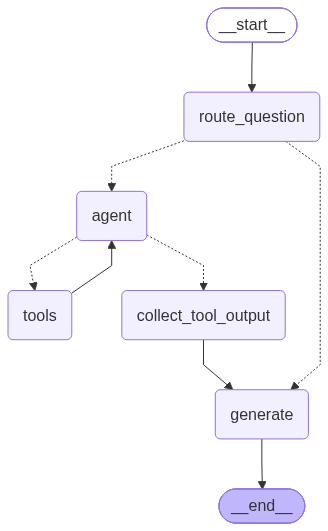

In [77]:
graph = graph_builder.compile()
graph

In [78]:
# Case 1: vector store only — domain-specific question about the PDF
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

ROUTING QUERY: According to the report, how will the adoption of electric vehicles impact oil demand?
ROUTING DECISION: needs_retrieval=True


In [79]:
print("=== CASE 1: Vector Store Only ===")
print(f"needs_retrieval : {result_vs['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_vs.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_vs.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_vs['generation']}")

=== CASE 1: Vector Store Only ===
needs_retrieval : True
retrieved_docs  : 3 docs
context preview : 

## Vector Store Results

Energy Agency, and McKinsey collectively project that EVs will account for between 40 and
60 ...

Generation:
According to the report, the adoption of electric vehicles (EVs) will impact oil demand by altering the supply chain dynamics. As EVs grow from 40 million to 300-500 million by 2030, this increase could lead to a material shift in oil price formation, potentially affecting global oil prices due to increased demand for oil for transportation and other sectors.


In [83]:
# Case 2: web search only — current information not in the PDF
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})

ROUTING QUERY: What is the current temperature in New Delhi?
ROUTING DECISION: needs_retrieval=True


In [84]:
print("=== CASE 2: Web Search Only ===")
print(f"needs_retrieval : {result_web['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_web.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_web.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_web['generation']}")


=== CASE 2: Web Search Only ===
needs_retrieval : True
retrieved_docs  : 3 docs
context preview : 

## Web Search Results

# New Delhi, Delhi

Current weather

11:49 AM

27°C

Sunny

Feels like

‎34°

Expect sunny skie...

Generation:
The current temperature in New Delhi is **25°C**.


In [85]:
# Case 3: both tools — requires document context AND current web data
query_both = "Compare what the EV report projects for 2030 oil demand and also tell me about the weather in mumbai"

result_both = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": ""})

ROUTING QUERY: Compare what the EV report projects for 2030 oil demand and also tell me about the weather in mumbai
ROUTING DECISION: needs_retrieval=True


In [86]:
print("=== CASE 3: Both Tools ===")
print(f"needs_retrieval : {result_both['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_both.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_both.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_both['generation']}")

=== CASE 3: Both Tools ===
needs_retrieval : True
retrieved_docs  : 6 docs
context preview : 

## Vector Store Results

— a meaningful but not transformative reduction against a global demand base of 100 to 105
mi...

Generation:
The EV report projects that by 2030, oil demand could reach 10 to 15 million barrels per day, which would bring absolute demand into structural decline. The IEA's Pledges Scenario and OPEC's World Oil Outlook project lower EV adoption rates, with the central scenario estimating only 2–3 million barrels per day displaced in that period.  

Regarding the weather in Mumbai:  
- The current weather shows temperatures ranging from 29°C (12 AM) to 30°C (6 PM), with conditions indicating a smoky haze. The temperature fluctuates throughout the day, and visibility is 6.6 km.


In [87]:
# Case 4: no retrieval — answerable from general knowledge
query_none = "Explain the difference between kinetic energy and potential energy."

result_none = graph.invoke({"query": query_none, "messages": [], "retrieved_docs": [], "context": ""})

ROUTING QUERY: Explain the difference between kinetic energy and potential energy.
ROUTING DECISION: needs_retrieval=False


In [88]:
print("=== CASE 4: No Retrieval ===")
print(f"needs_retrieval : {result_none['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_none.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_none.get('context', '') or '(none)'}")
print(f"\nGeneration:\n{result_none['generation']}")

=== CASE 4: No Retrieval ===
needs_retrieval : False
retrieved_docs  : 0 docs
context preview : (none)

Generation:
Kinetic energy is the energy an object has due to its motion, and it depends on both mass and velocity. When an object moves, it converts kinetic energy into other forms like heat or sound. Potential energy, on the other hand, is the energy stored in an object due to its position or shape. For example, a ball held above the ground has potential energy, and when it falls, that potential energy is converted into kinetic energy. Both forms of energy are part of the total energy system, but they are not all the same. Kinetic energy is directly proportional to motion, while potential energy is proportional to position or shape. They can be converted into each other, making them interconvertible in a closed system.


In [89]:
result_both["messages"]

[AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:0.6b', 'created_at': '2026-10-19T08:17:10.564619704Z', 'done': True, 'done_reason': 'stop', 'total_duration': 13406995234, 'load_duration': 914635, 'prompt_eval_count': 467, 'prompt_eval_duration': 265406000, 'eval_count': 359, 'eval_duration': 13103646000, 'logprobs': None, 'model_name': 'qwen3:0.6b', 'model_provider': 'ollama'}, id='lc_run--01a1533c-3544-7640-bed2-510884e0a1b5-0', tool_calls=[{'name': 'vector_store_search', 'args': {'k': 3, 'query': 'oil demand projections for 2030'}, 'id': '262dfa01-7378-46d3-82e2-2278d006e8aa', 'type': 'tool_call'}, {'name': 'web_search', 'args': {'query': 'mumbai weather in 2024'}, 'id': 'a7b1bdef-cc3b-44b5-b178-29f4f2fe7fc4', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 467, 'output_tokens': 359, 'total_tokens': 826}),
 ToolMessage(content="\n\n## Vector Store Results\n\n— a meaningful but not transformative reduction against a global 